# Ajuste fino de hiperparámetros: LightGBM

Modelo elegido en `flight_delay_modeling_v2.ipynb` (veredicto: LightGBM supera de forma significativa a regresión logística, XGBoost y K-means). Este notebook busca mejores hiperparámetros y mide, **una sola vez en prueba**, si el ajuste realmente ayuda.

**Qué NO se repite** (ya hecho en `Ingesta_y_procesamiento_de_datos.ipynb`): carga de bronze, calidad de datos, EDA, auditoría de fuga, eliminación de columnas con fuga y de objetivos nulos. La entrada es la **capa silver**.

**Variables de modelado:** las construye `src/utils/model_features.py` (las mismas de la v2) y las guarda en `data/gold/model_features/`. Si ya existen y nada cambió, **se leen de ahí** en segundos; si cambia la configuración o silver, se reconstruyen (y se repite la verificación anti-fuga).

**Método (tres etapas)**

| Etapa | Qué hace | Datos |
|---|---|---|
| 1. Búsqueda | Optuna (TPE + poda de pruebas malas) sobre un **proxy rápido**: submuestra de entrenamiento y tasa de aprendizaje alta. Maximiza **PR-AUC en validación**. Incluye como primer intento los parámetros de la v2. | entrenamiento (submuestra) / validación |
| 2. Confirmación | Las mejores `TOP_K` configuraciones se reentrenan con **toda** la muestra de entrenamiento y tasa de aprendizaje baja. Se elige la mejor en validación. | entrenamiento / validación |
| 3. Prueba (una vez) | Se compara el ajustado contra los parámetros de la v2 en prueba, con intervalo de confianza de la diferencia. Se reentrena con entrenamiento + validación. | prueba |

**Reglas:** la prueba no se usa para elegir nada. Los parámetros dependientes del tamaño de datos (`min_data_in_leaf`) se buscan como **fracción** de las filas, para que el proxy y el entrenamiento completo sean comparables.

## 0. Configuración

In [2]:
import json
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import optuna
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score

sys.path.insert(0, str(Path("utils").resolve()))      # el notebook corre desde src/
import model_features as mf
import model_eval as me

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [3]:
OUT_DIR   = Path("../outputs/outputs_modeling")
CACHE_DIR = Path("../data/gold/model_features")
TARGET    = mf.TARGET
SEED      = 42

# Mismas decisiones de la v2 (partición, horizonte de predicción, historial).
cfg = mf.FeatureConfig(
    silver_glob="../data/silver/flights/**/*.parquet",
    train_end="2024-12-31", val_end="2025-08-31", warmup_days=60,
    hist_window_days=30, hist_smooth=50, pred_horizon_min=240,
    seed=SEED, memory_limit="14GB", temp_dir="duckdb_tmp",
)
N_TRAIN = 4_000_000          # debe coincidir con la v2 para comparar con sus resultados
N_EVAL  = 1_000_000

# Etapa 1: búsqueda (proxy rápido)
N_TUNE_TRAIN      = 1_000_000
N_TUNE_VAL        = 500_000
SEARCH_LR         = 0.1
SEARCH_MAX_TREES  = 1500
SEARCH_EARLY_STOP = 50
N_TRIALS          = 40
TIMEOUT_MIN       = 75       # tope de tiempo de la búsqueda

# Etapa 2: confirmación con todos los datos
TOP_K            = 3
FINAL_LR         = 0.03
FINAL_MAX_TREES  = 4000
FINAL_EARLY_STOP = 100

# Etapa 3
RUN_BASELINE = True          # reentrena los parámetros de la v2 sobre estas mismas muestras
RUN_REFIT    = True          # reentrena el ajustado con entrenamiento + validación
COST_FP, COST_FN = 1, 3      # mismo supuesto de costo que la v2
BOOT_ROWS, BOOT_N = 300_000, 100

OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / "figures").mkdir(exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(OUT_DIR / "figures" / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

## 1. Variables de modelado (desde silver, con caché)

In [4]:
t0 = time.time()
data = mf.load_or_build(cfg, CACHE_DIR, N_TRAIN, N_EVAL)
train, val, test, PRIOR = data["train"], data["val"], data["test"], data["prior"]
print(("Leído de la caché (gold)" if data["from_cache"] else "Construido y guardado en la caché (gold)") + f" en {time.time() - t0:,.0f}s")

FULL = mf.feature_lists(cfg)["full"]
cat_levels = mf.fit_cat_levels(train)
matrix = lambda df: mf.make_matrix(df, FULL, cat_levels)
y_train, y_val, y_test = (d[TARGET].values for d in (train, val, test))
pd.DataFrame({"filas": [len(train), len(val), len(test)],
              "desde": [d.FlightDate.min().date() for d in (train, val, test)],
              "hasta": [d.FlightDate.max().date() for d in (train, val, test)],
              "tasa_retraso": [y_train.mean(), y_val.mean(), y_test.mean()]}, index=["train", "val", "test"])

Tablas auxiliares listas en 53s | prior = 0.2084
  train: 4,000,000 filas en 247s
  val: 1,000,000 filas en 54s
  test: 1,000,000 filas en 59s
✔ Verificación anti-fuga: variables históricas y de estado del día coinciden con el recálculo a mano.
Construido y guardado en la caché (gold) en 459s


,filas,desde,hasta,tasa_retraso
train,4000000,2022-03-02,2024-12-31,0.2093
val,1000000,2025-01-01,2025-08-31,0.2227
test,1000000,2025-09-01,2026-08-31,0.2292


## 2. Parámetros de partida (los de la v2) y funciones

En la v2, LightGBM usó `num_leaves=63`, `min_child_samples=2000`, `feature_fraction=0.7`, `bagging_fraction=0.8`, `lambda_l2=20`, `cat_smooth=100`, `min_data_per_group=500` y tasa de aprendizaje 0,03. Se nombran aquí con los nombres nativos de LightGBM.

In [5]:
BASE = dict(objective="binary", bagging_freq=1, max_cat_to_onehot=4, verbosity=-1, seed=SEED)
BASELINE_PARAMS = dict(learning_rate=0.03, num_leaves=63, max_depth=-1, min_data_in_leaf=2000,
                       feature_fraction=0.7, bagging_fraction=0.8, lambda_l1=0.0, lambda_l2=20.0,
                       min_gain_to_split=0.0, path_smooth=0.0, cat_smooth=100.0, cat_l2=10.0,
                       min_data_per_group=500, max_cat_threshold=32)

# Dataset reutilizable entre pruebas: sin pre-filtrado de variables (si no, no se puede variar min_data_in_leaf).
DS_PARAMS = {"feature_pre_filter": False, "max_bin": 255}

def make_datasets(tr, va):
    dtr = lgb.Dataset(matrix(tr), tr[TARGET].values, params=DS_PARAMS, free_raw_data=False)
    dva = lgb.Dataset(matrix(va), va[TARGET].values, reference=dtr, free_raw_data=False)
    return dtr, dva

def to_params(p, n_rows, lr):
    """Hiperparámetros sugeridos → parámetros de LightGBM; min_data_in_leaf se escala con las filas."""
    return dict(learning_rate=lr, num_leaves=p["num_leaves"], max_depth=p["max_depth"],
                min_data_in_leaf=max(20, int(p["min_child_frac"] * n_rows)),
                feature_fraction=p["feature_fraction"], bagging_fraction=p["bagging_fraction"],
                lambda_l1=p["lambda_l1"], lambda_l2=p["lambda_l2"], min_gain_to_split=p["min_split_gain"],
                path_smooth=p["path_smooth"], cat_smooth=p["cat_smooth"], cat_l2=p["cat_l2"],
                min_data_per_group=p["min_data_per_group"], max_cat_threshold=p["max_cat_threshold"])

## 3. Etapa 1 — Búsqueda con Optuna (proxy rápido)

Espacio de búsqueda: complejidad del árbol (`num_leaves`, `max_depth`), tamaño mínimo de hoja (como fracción de las filas), submuestreo de filas y columnas, regularización L1/L2, ganancia mínima, suavizado de hojas y los parámetros de las **categóricas de muchos valores** (ruta, aeropuertos): `cat_smooth`, `cat_l2`, `min_data_per_group`, `max_cat_threshold`. El primer intento es la configuración de la v2, así que la búsqueda nunca queda por debajo de ella en el proxy.

In [6]:
tr_t = train.sample(min(N_TUNE_TRAIN, len(train)), random_state=SEED)
va_t = val.sample(min(N_TUNE_VAL, len(val)), random_state=SEED)
dtr_t, dva_t = make_datasets(tr_t, va_t)
print(f"Proxy: {len(tr_t):,} filas de entrenamiento, {len(va_t):,} de validación, tasa de aprendizaje {SEARCH_LR}")

def suggest(trial):
    return dict(
        num_leaves=trial.suggest_int("num_leaves", 15, 255, log=True),
        max_depth=trial.suggest_categorical("max_depth", [-1, 6, 8, 10, 12]),
        min_child_frac=trial.suggest_float("min_child_frac", 5e-5, 3e-3, log=True),
        feature_fraction=trial.suggest_float("feature_fraction", 0.4, 1.0),
        bagging_fraction=trial.suggest_float("bagging_fraction", 0.5, 1.0),
        lambda_l1=trial.suggest_float("lambda_l1", 1e-3, 50.0, log=True),
        lambda_l2=trial.suggest_float("lambda_l2", 1e-2, 200.0, log=True),
        min_split_gain=trial.suggest_float("min_split_gain", 0.0, 0.5),
        path_smooth=trial.suggest_float("path_smooth", 0.0, 50.0),
        cat_smooth=trial.suggest_float("cat_smooth", 5.0, 200.0, log=True),
        cat_l2=trial.suggest_float("cat_l2", 1.0, 100.0, log=True),
        min_data_per_group=trial.suggest_int("min_data_per_group", 50, 2000, log=True),
        max_cat_threshold=trial.suggest_int("max_cat_threshold", 8, 128, log=True),
    )

def prune_callback(trial, every=25):
    def _cb(env):
        it = env.iteration + 1
        if it % every:
            return
        for _, metric, value, _ in env.evaluation_result_list:
            if metric == "average_precision":
                trial.report(value, it)
                if trial.should_prune():
                    raise optuna.TrialPruned()
    return _cb

def objective(trial):
    params = {**BASE, **to_params(suggest(trial), len(tr_t), SEARCH_LR), "metric": ["average_precision", "binary_logloss"]}
    booster = lgb.train(params, dtr_t, num_boost_round=SEARCH_MAX_TREES, valid_sets=[dva_t], valid_names=["val"],
                        callbacks=[lgb.early_stopping(SEARCH_EARLY_STOP, first_metric_only=True, verbose=False),
                                   prune_callback(trial)])
    trial.set_user_attr("best_iter", booster.best_iteration)
    trial.set_user_attr("val_logloss", booster.best_score["val"]["binary_logloss"])
    return booster.best_score["val"]["average_precision"]

study = optuna.create_study(direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=10),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=100))
# Primer intento: la configuración de la v2 expresada en este espacio.
study.enqueue_trial(dict(num_leaves=63, max_depth=-1, min_child_frac=2000 / N_TRAIN, feature_fraction=0.7,
                         bagging_fraction=0.8, lambda_l1=1e-3, lambda_l2=20.0, min_split_gain=0.0, path_smooth=0.0,
                         cat_smooth=100.0, cat_l2=10.0, min_data_per_group=500, max_cat_threshold=32))
t0 = time.time()
study.optimize(objective, n_trials=N_TRIALS, timeout=TIMEOUT_MIN * 60)
states = pd.Series([t.state.name for t in study.trials]).value_counts().to_dict()
print(f"Búsqueda terminada en {(time.time() - t0) / 60:,.1f} min | pruebas: {states}")

Proxy: 1,000,000 filas de entrenamiento, 500,000 de validación, tasa de aprendizaje 0.1
Búsqueda terminada en 12.2 min | pruebas: {'COMPLETE': 20, 'PRUNED': 20}


In [7]:
trials = study.trials_dataframe(attrs=("number", "value", "state", "user_attrs", "params"))
trials.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in trials.columns]
done = trials[trials.state == "COMPLETE"].sort_values("value", ascending=False)
trials.to_csv(OUT_DIR / "tuning_trials.csv", index=False)
v2_value = trials.loc[trials.number == 0, "value"].iloc[0]
print(f"PR-AUC de validación (proxy): configuración v2 = {v2_value:.4f} | mejor encontrada = {done.value.iloc[0]:.4f} "
      f"(+{done.value.iloc[0] - v2_value:.4f})")
done.head(10)

PR-AUC de validación (proxy): configuración v2 = 0.5183 | mejor encontrada = 0.5233 (+0.0050)


,number,value,state,best_iter,val_logloss,bagging_fraction,cat_l2,cat_smooth,feature_fraction,lambda_l1,lambda_l2,max_cat_threshold,max_depth,min_child_frac,min_data_per_group,min_split_gain,num_leaves,path_smooth
37,37,0.5233,COMPLETE,401.0000,0.4507,0.8624,2.7608,5.7315,0.7688,0.0016,3.4357,8,6,0.0002,1356,0.2893,58,23.3401
24,24,0.5232,COMPLETE,309.0000,0.4506,0.7280,5.2105,5.4745,0.7630,0.0014,2.2877,10,6,0.0004,1710,0.1509,47,11.2018
27,27,0.5219,COMPLETE,353.0000,0.4512,0.8093,4.1338,7.2680,0.8781,0.0314,4.7154,10,6,0.0006,1618,0.1599,42,17.6248
18,18,0.5217,COMPLETE,253.0000,0.4513,0.9920,2.7640,22.9361,0.8446,0.0015,1.7649,11,6,0.0003,1149,0.2420,72,21.4400
28,28,0.5217,COMPLETE,227.0000,0.4513,0.9177,3.0200,13.2294,0.7051,0.0056,3.5966,9,6,0.0001,965,0.2518,76,24.1199
38,38,0.5216,COMPLETE,256.0000,0.4512,0.9157,1.3635,7.0752,0.8849,0.0604,3.1293,9,6,0.0003,1665,0.2377,40,23.3102
14,14,0.5215,COMPLETE,408.0000,0.4513,0.6868,8.1251,6.7214,0.8995,0.0013,27.9837,10,6,0.0002,881,0.1616,33,14.4616
8,8,0.5206,COMPLETE,193.0000,0.4518,0.9304,4.7340,7.7804,0.8908,0.0011,1.5730,19,6,0.0003,1620,0.2087,68,11.1054
9,9,0.5201,COMPLETE,197.0000,0.4520,0.6424,65.5438,13.9759,0.5805,0.0015,4.1856,11,8,0.0004,120,0.2513,64,2.5739
7,7,0.5196,COMPLETE,406.0000,0.4520,0.6449,40.4897,124.4807,0.4462,0.0057,99.6914,95,6,0.0001,99,0.4041,36,31.6702


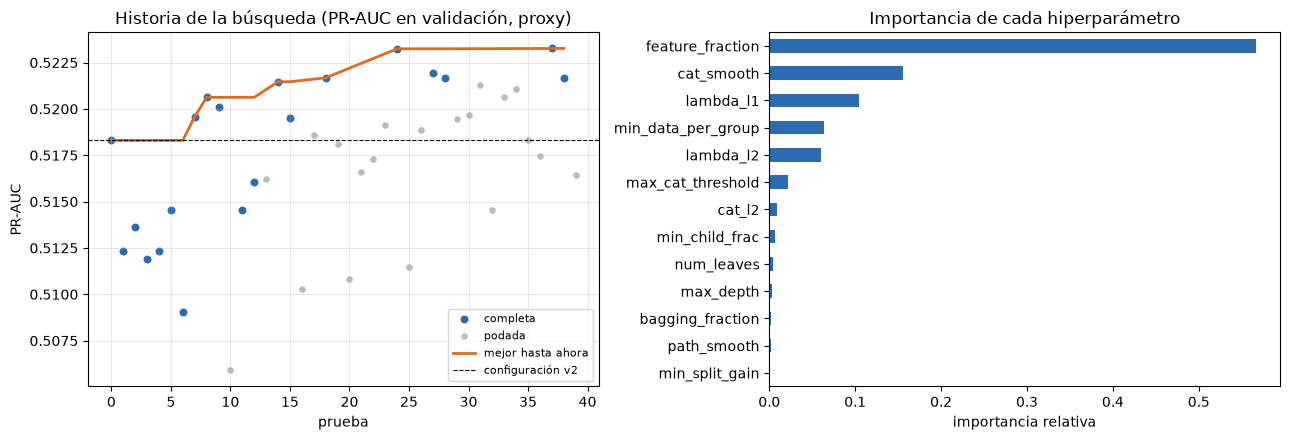

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ok = trials[trials.state == "COMPLETE"]; pr = trials[trials.state == "PRUNED"]
ax[0].scatter(ok.number, ok.value, c="#2b6cb0", s=22, label="completa")
ax[0].scatter(pr.number, pr.value, c="#bbbbbb", s=14, label="podada")
ax[0].plot(ok.number, ok.value.cummax(), c="#dd6b20", lw=2, label="mejor hasta ahora")
ax[0].axhline(v2_value, c="k", ls="--", lw=0.8, label="configuración v2")
ax[0].set(title="Historia de la búsqueda (PR-AUC en validación, proxy)", xlabel="prueba", ylabel="PR-AUC")
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
try:
    imp = pd.Series(optuna.importance.get_param_importances(study)).sort_values()
    imp.plot.barh(ax=ax[1], color="#2b6cb0")
    ax[1].set(title="Importancia de cada hiperparámetro", xlabel="importancia relativa")
except Exception as e:
    ax[1].text(0.5, 0.5, f"No se pudo calcular la importancia:\n{e}", ha="center"); ax[1].axis("off")
save_fig("tuning_search")

## 4. Etapa 2 — Confirmación con todos los datos

El proxy usa menos filas y una tasa de aprendizaje alta, así que su orden no es perfecto. Las `TOP_K` mejores configuraciones se reentrenan con **toda** la muestra de entrenamiento y tasa de aprendizaje `FINAL_LR`, con parada temprana por *log loss* en validación (igual que la v2). La elección se hace por PR-AUC de **validación**. Junto a ellas se reentrena la configuración de la v2 como referencia.

In [9]:
t0 = time.time()
dtr_f, dva_f = make_datasets(train, val)
X_val, X_test = matrix(val), matrix(test)

def fit_final(name, params):
    p = {**BASE, **params, "metric": ["binary_logloss", "average_precision"]}
    evals, t1 = {}, time.time()
    booster = lgb.train(p, dtr_f, num_boost_round=FINAL_MAX_TREES, valid_sets=[dva_f], valid_names=["val"],
                        callbacks=[lgb.early_stopping(FINAL_EARLY_STOP, first_metric_only=True, verbose=False),
                                   lgb.record_evaluation(evals)])
    p_val = booster.predict(X_val, num_iteration=booster.best_iteration)
    print(f"{name}: {booster.best_iteration} árboles | PR-AUC val {average_precision_score(y_val, p_val):.4f} | {time.time() - t1:,.0f}s")
    return {"name": name, "params": params, "booster": booster, "evals": evals, "p_val": p_val}

cands = []
if RUN_BASELINE:
    cands.append(fit_final("v2 (referencia)", {**BASELINE_PARAMS, "learning_rate": FINAL_LR}))
top = done[done.number != 0].head(TOP_K)      # la prueba 0 es la configuración v2: ya se reentrena como referencia
for rank, (_, row) in enumerate(top.iterrows(), start=1):
    p = {k: row[k] for k in ["num_leaves", "max_depth", "min_child_frac", "feature_fraction", "bagging_fraction",
                              "lambda_l1", "lambda_l2", "min_split_gain", "path_smooth", "cat_smooth", "cat_l2",
                              "min_data_per_group", "max_cat_threshold"]}
    p["num_leaves"], p["max_depth"], p["min_data_per_group"], p["max_cat_threshold"] = (
        int(p["num_leaves"]), int(p["max_depth"]), int(p["min_data_per_group"]), int(p["max_cat_threshold"]))
    cands.append(fit_final(f"ajustado #{rank} (prueba {int(row.number)})", to_params(p, len(train), FINAL_LR)))
print(f"Etapa 2 terminada en {(time.time() - t0) / 60:,.1f} min")

stage2 = pd.DataFrame([{"modelo": c["name"], "árboles": c["booster"].best_iteration,
                        "PR-AUC val": average_precision_score(y_val, c["p_val"]),
                        "ROC-AUC val": roc_auc_score(y_val, c["p_val"]),
                        "log loss val": log_loss(y_val, np.clip(c["p_val"], 1e-6, 1 - 1e-6))} for c in cands]).set_index("modelo")
stage2

v2 (referencia): 971 árboles | PR-AUC val 0.5266 | 508s
ajustado #1 (prueba 37): 1548 árboles | PR-AUC val 0.5299 | 576s
ajustado #2 (prueba 24): 2178 árboles | PR-AUC val 0.5295 | 637s
ajustado #3 (prueba 27): 2199 árboles | PR-AUC val 0.5290 | 711s
Etapa 2 terminada en 40.7 min


,árboles,PR-AUC val,ROC-AUC val,log loss val
modelo,,,,
v2 (referencia),971,0.5266,0.7511,0.4491
ajustado #1 (prueba 37),1548,0.5299,0.7535,0.4477
ajustado #2 (prueba 24),2178,0.5295,0.7535,0.4478
ajustado #3 (prueba 27),2199,0.5290,0.7531,0.4480


Elegido por validación entre los ajustados: ajustado #1 (prueba 37)


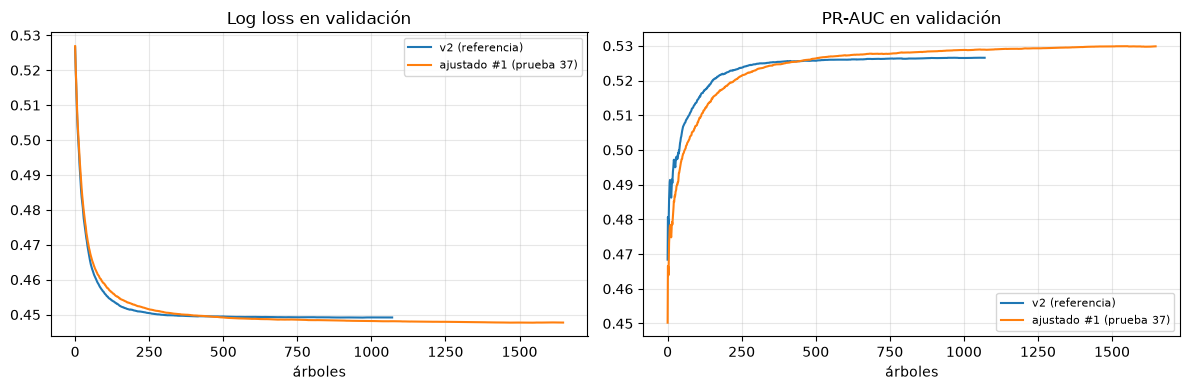

In [10]:
tuned_cands = [c for c in cands if not c["name"].startswith("v2")]
tuned = max(tuned_cands, key=lambda c: average_precision_score(y_val, c["p_val"]))
baseline = next((c for c in cands if c["name"].startswith("v2")), None)
print(f"Elegido por validación entre los ajustados: {tuned['name']}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for c in ([baseline] if baseline else []) + [tuned]:
    for a, metric in zip(ax, ["binary_logloss", "average_precision"]):
        a.plot(c["evals"]["val"][metric], label=c["name"])
ax[0].set(title="Log loss en validación", xlabel="árboles"); ax[1].set(title="PR-AUC en validación", xlabel="árboles")
for a in ax: a.legend(fontsize=8); a.grid(alpha=0.3)
save_fig("tuning_learning_curves")

## 5. Etapa 3 — Prueba (se mira una sola vez)

Se compara el modelo ajustado con la configuración de la v2 **en las mismas muestras**. Se reporta el intervalo de confianza 95 % de la diferencia (bootstrap pareado) para no confundir ruido con mejora. Umbrales: el que minimiza el costo en validación, y el común teórico `COST_FP / (COST_FP + COST_FN)`.

In [11]:
T_COMMON = COST_FP / (COST_FP + COST_FN)
models_eval = {"ajustado": tuned}
if baseline:
    models_eval["v2 (referencia)"] = baseline
for name, c in models_eval.items():
    c["p_test"] = c["booster"].predict(X_test, num_iteration=c["booster"].best_iteration)

rows = []
for name, c in models_eval.items():
    thr = me.best_cost_threshold(y_val, c["p_val"], COST_FP, COST_FN)
    r = me.evaluate_model(name, y_test, c["p_test"], thr, COST_FP, COST_FN)
    r["costo_x1000 (umbral común)"] = me.evaluate_model(name, y_test, c["p_test"], T_COMMON, COST_FP, COST_FN)["costo_x1000"]
    r["árboles"] = c["booster"].best_iteration
    rows.append(r)
cmp = pd.DataFrame(rows).set_index("modelo")
display(cmp[["roc_auc", "pr_auc", "brier", "log_loss", "ece", "umbral", "precision", "recall", "f1",
             "costo_x1000", "costo_x1000 (umbral común)", "árboles"]])
cmp.to_csv(OUT_DIR / "tuning_test_comparison.csv")

,roc_auc,pr_auc,brier,log_loss,ece,umbral,precision,recall,f1,costo_x1000,costo_x1000 (umbral común),árboles
modelo,,,,,,,,,,,,
ajustado,0.7629,0.5507,0.1424,0.4482,0.0021,0.2559,0.4548,0.5964,0.5161,441.4080,441.1200,1548
v2 (referencia),0.7601,0.5468,0.1431,0.4500,0.0019,0.2564,0.4531,0.5902,0.5126,445.1070,444.5850,971


In [12]:
verdict_txt = "Sin referencia v2 (RUN_BASELINE = False): no hay comparación."
if baseline:
    d_pr, lo_pr, hi_pr = me.paired_bootstrap_diff(y_test, tuned["p_test"], baseline["p_test"], average_precision_score, BOOT_N, BOOT_ROWS, SEED)
    d_roc, lo_roc, hi_roc = me.paired_bootstrap_diff(y_test, tuned["p_test"], baseline["p_test"], roc_auc_score, BOOT_N, BOOT_ROWS, SEED)
    d_ll = log_loss(y_test, tuned["p_test"]) - log_loss(y_test, baseline["p_test"])
    display(pd.DataFrame({"Δ (ajustado − v2)": [d_pr, d_roc], "IC95": [f"[{lo_pr:+.4f}, {hi_pr:+.4f}]", f"[{lo_roc:+.4f}, {hi_roc:+.4f}]"]},
                         index=["PR-AUC", "ROC-AUC"]))
    if lo_pr > 0:
        size = "marginal (< 0,002 de PR-AUC)" if d_pr < 0.002 else "relevante"
        verdict_txt = f"El ajuste MEJORA PR-AUC de forma significativa: {d_pr:+.4f} (IC95 [{lo_pr:+.4f}, {hi_pr:+.4f}]); mejora {size}."
    elif hi_pr < 0:
        verdict_txt = f"El ajuste EMPEORA PR-AUC en prueba ({d_pr:+.4f}); conviene conservar los parámetros de la v2."
    else:
        verdict_txt = (f"Sin diferencia significativa en PR-AUC ({d_pr:+.4f}, IC95 [{lo_pr:+.4f}, {hi_pr:+.4f}]): "
                       "los parámetros de la v2 ya estaban cerca del óptimo; el ajuste no justifica cambiarlos.")
print("=" * 78); print("VEREDICTO DEL AJUSTE"); print("=" * 78)
print("•", verdict_txt)
print(f"• Log loss ajustado − v2 en prueba: {d_ll:+.5f} (negativo = mejores probabilidades)" if baseline else "")

,Δ (ajustado − v2),IC95
PR-AUC,0.0041,"[+0.0034, +0.0047]"
ROC-AUC,0.0028,"[+0.0023, +0.0032]"


VEREDICTO DEL AJUSTE
• El ajuste MEJORA PR-AUC de forma significativa: +0.0041 (IC95 [+0.0034, +0.0047]); mejora relevante.
• Log loss ajustado − v2 en prueba: -0.00186 (negativo = mejores probabilidades)


## 6. Reentrenar con entrenamiento + validación y guardar

Con los parámetros elegidos y el número de árboles de la parada temprana, se reentrena con entrenamiento **y** validación (más datos recientes). Se evalúa en prueba con el umbral común por costo.

In [13]:
final_booster, refit_row = tuned["booster"], None
if RUN_REFIT:
    t0 = time.time()
    both = pd.concat([train, val], ignore_index=True)
    d_both = lgb.Dataset(matrix(both), both[TARGET].values, params=DS_PARAMS, free_raw_data=False)
    # min_data_in_leaf se reescala a las filas totales para mantener la misma fracción.
    p = {**BASE, **tuned["params"], "metric": "binary_logloss"}
    p["min_data_in_leaf"] = max(20, int(tuned["params"]["min_data_in_leaf"] * len(both) / len(train)))
    final_booster = lgb.train(p, d_both, num_boost_round=tuned["booster"].best_iteration)
    p_refit = final_booster.predict(X_test)
    refit_row = pd.DataFrame([
        me.evaluate_model("ajustado (solo entrenamiento)", y_test, tuned["p_test"], T_COMMON, COST_FP, COST_FN),
        me.evaluate_model("ajustado (entrenamiento + validación)", y_test, p_refit, T_COMMON, COST_FP, COST_FN),
    ]).set_index("modelo")[["roc_auc", "pr_auc", "brier", "log_loss", "ece", "precision", "recall", "f1", "costo_x1000"]]
    print(f"Reentrenado en {(time.time() - t0) / 60:,.1f} min | umbral común = {T_COMMON:.3f}")
    display(refit_row)

Reentrenado en 10.3 min | umbral común = 0.250


,roc_auc,pr_auc,brier,log_loss,ece,precision,recall,f1,costo_x1000
modelo,,,,,,,,,
ajustado (solo entrenamiento),0.7629,0.5507,0.1424,0.4482,0.0021,0.4484,0.6077,0.5160,441.1200
ajustado (entrenamiento + validación),0.7656,0.5545,0.1418,0.4464,0.0034,0.4530,0.6086,0.5194,437.6130


In [14]:
tp = tuned["params"]
sklearn_params = dict(
    objective="binary", learning_rate=tp["learning_rate"], num_leaves=int(tp["num_leaves"]), max_depth=int(tp["max_depth"]),
    min_child_samples=int(tp["min_data_in_leaf"]), subsample=tp["bagging_fraction"], subsample_freq=1,
    colsample_bytree=tp["feature_fraction"], reg_alpha=tp["lambda_l1"], reg_lambda=tp["lambda_l2"],
    min_split_gain=tp["min_gain_to_split"], path_smooth=tp["path_smooth"], cat_smooth=tp["cat_smooth"],
    cat_l2=tp["cat_l2"], min_data_per_group=int(tp["min_data_per_group"]), max_cat_threshold=int(tp["max_cat_threshold"]),
    max_cat_to_onehot=4, n_estimators=int(tuned["booster"].best_iteration), random_state=SEED,
)
print("Parámetros para copiar a LGB_PARAMS de la v2 (nombres de scikit-learn; sin parada temprana → n_estimators fijo):\n")
print(json.dumps(sklearn_params, indent=2))

out = {"veredicto": verdict_txt, "parametros_lightgbm": {k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in tp.items()},
       "parametros_sklearn": sklearn_params, "arboles": int(tuned["booster"].best_iteration),
       "pr_auc_val": float(average_precision_score(y_val, tuned["p_val"])),
       "pr_auc_prueba": float(average_precision_score(y_test, tuned["p_test"])),
       "config_busqueda": {"n_trials": N_TRIALS, "n_tune_train": N_TUNE_TRAIN, "search_lr": SEARCH_LR, "final_lr": FINAL_LR}}
with open(OUT_DIR / "best_lgbm_params.json", "w") as f:
    json.dump(out, f, indent=2, ensure_ascii=False, default=float)
final_booster.save_model(str(OUT_DIR / "lgbm_ajustado.txt"))
print("\nGuardado en", OUT_DIR.resolve())

Parámetros para copiar a LGB_PARAMS de la v2 (nombres de scikit-learn; sin parada temprana → n_estimators fijo):

{
  "objective": "binary",
  "learning_rate": 0.03,
  "num_leaves": 58,
  "max_depth": 6,
  "min_child_samples": 666,
  "subsample": 0.8624042648439187,
  "subsample_freq": 1,
  "colsample_bytree": 0.7687778810867828,
  "reg_alpha": 0.0016328449169203338,
  "reg_lambda": 3.435738699306991,
  "min_split_gain": 0.289251457265169,
  "path_smooth": 23.340079974709468,
  "cat_smooth": 5.731463506170709,
  "cat_l2": 2.760775849544561,
  "min_data_per_group": 1356,
  "max_cat_threshold": 8,
  "max_cat_to_onehot": 4,
  "n_estimators": 1548,
  "random_state": 42
}



Guardado en C:\Users\jeronimo.acosta\Desktop\Uni\Proyecto Integrador\Missed-Flight-Risk-Percentage-Analysis-US\outputs\outputs_modeling


In [15]:
# ============ Capa ORO con el modelo FINAL (pegar al final de flight_delay_tuning.ipynb) ============
import json
import time
import duckdb
import lightgbm as lgb
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

GOLD_DIR   = Path("../data/gold/pred_vs_real")
GOLD_SET   = "prueba"                      # para meses posteriores a 2026-08 se usaría "prospectivo"
GOLD_MODEL = "LightGBM ajustado (entrenamiento + validación)"
GOLD_FILE  = OUT_DIR / "lgbm_ajustado.txt"
GOLD_THR   = COST_FP / (COST_FP + COST_FN)  # umbral común por costo (0,25): el modelo reentrenado ya no tiene validación limpia
GOLD_MIN_ROWS = 500                         # subgrupos con menos vuelos no se guardan

FULL_G = mf.feature_lists(cfg)["full"]
test_g = mf.load_or_build(cfg, CACHE_DIR, N_TRAIN, N_EVAL)["test"]      # se lee de la caché (segundos)
booster_g = lgb.Booster(model_file=str(GOLD_FILE))
X_g = test_g[FULL_G].copy()
for _c in mf.CAT_COLS:
    X_g[_c] = X_g[_c].astype("category")                                 # el modelo remapea las categorías con las que se entrenó
GOLD_P = booster_g.predict(X_g)
y_g = test_g[mf.TARGET].astype(int).values
if "p_refit" in globals():                                               # comprobación: el modelo guardado reproduce lo que había en memoria
    assert np.allclose(GOLD_P, p_refit, atol=1e-6), "El modelo guardado no reproduce las predicciones en memoria"
print(f"{GOLD_MODEL}: {len(GOLD_P):,} vuelos de prueba | PR-AUC {average_precision_score(y_g, GOLD_P):.4f} | "
      f"ROC-AUC {roc_auc_score(y_g, GOLD_P):.4f} | umbral {GOLD_THR:.2f}")

LightGBM ajustado (entrenamiento + validación): 1,000,000 vuelos de prueba | PR-AUC 0.5545 | ROC-AUC 0.7656 | umbral 0.25


In [16]:
_DOW = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
_BANDS = ["Madrugada (0–5 h)", "Mañana (6–11 h)", "Tarde (12–17 h)", "Noche (18–24 h)"]
_SEASONS = ["Invierno (dic–feb)", "Primavera (mar–may)", "Verano (jun–ago)", "Otoño (sep–nov)"]
_season = lambda m: _SEASONS[0] if m in (12, 1, 2) else _SEASONS[1] if m in (3, 4, 5) else _SEASONS[2] if m in (6, 7, 8) else _SEASONS[3]

gold = pd.DataFrame({
    "fecha": pd.to_datetime(test_g.FlightDate).dt.normalize().values,
    "aerolinea": test_g.Reporting_Airline.values, "origen": test_g.Origin.values,
    "hora": test_g.dep_hour.astype(int).values, "mes": test_g.Month.astype(int).values,
    "dia_semana": test_g.DayOfWeek.astype(int).values, "y": y_g, "p": GOLD_P})
gold["periodo"] = pd.to_datetime(gold.fecha).dt.strftime("%Y-%m")
gold["franja"] = pd.cut(gold.hora, [-1, 5, 11, 17, 24], labels=_BANDS).astype(str)
gold["temporada"] = gold.mes.map(_season)
gold["dia_nombre"] = gold.dia_semana.map(lambda d: _DOW[d - 1])
gold["hora_txt"] = gold.hora.map(lambda h: f"{h:02d} h")
gold["alerta"] = (gold.p >= GOLD_THR).astype(int)
for _c, _a, _b in [("tp", 1, 1), ("fp", 1, 0), ("fn", 0, 1), ("tn", 0, 0)]:
    gold[_c] = ((gold.alerta == _a) & (gold.y == _b)).astype(int)

def gold_group_table(dimension, col, order=None, min_rows=GOLD_MIN_ROWS):
    key = gold[col] if col else pd.Series("Todos los vuelos", index=gold.index)
    rows = []
    for k, g in gold.groupby(key, observed=True, sort=False):
        n, pos = len(g), int(g.y.sum())
        if n < min_rows or pos in (0, n):
            continue
        tp, fp, fn, tn = (int(g[c].sum()) for c in ("tp", "fp", "fn", "tn"))
        prec, rec = (tp / (tp + fp) if tp + fp else 0.0), (tp / (tp + fn) if tp + fn else 0.0)
        rows.append({"dimension": dimension, "grupo": str(k), "vuelos": n, "retrasados": pos, "tasa_real": pos / n,
                     "prob_media": float(g.p.mean()), "sesgo": float(g.p.mean()) / (pos / n),
                     "roc_auc": roc_auc_score(g.y, g.p), "pr_auc": average_precision_score(g.y, g.p),
                     "brier": brier_score_loss(g.y, g.p), "umbral": GOLD_THR, "alertas": tp + fp,
                     "tp": tp, "fp": fp, "fn": fn, "tn": tn, "precision": prec, "recall": rec,
                     "f1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0})
    t = pd.DataFrame(rows)
    if len(t):
        t["orden"] = t.grupo.map(order) if order else t.vuelos.rank(ascending=False, method="first")
    return t

_dims = [("Global", None, None), ("Aerolínea", "aerolinea", None), ("Aeropuerto de origen", "origen", None),
         ("Franja horaria", "franja", {b: i for i, b in enumerate(_BANDS)}),
         ("Temporada", "temporada", {b: i for i, b in enumerate(_SEASONS)}),
         ("Mes", "periodo", {m: i for i, m in enumerate(sorted(gold.periodo.unique()))}),
         ("Día de la semana", "dia_nombre", {d: i for i, d in enumerate(_DOW)}),
         ("Hora de salida", "hora_txt", {f"{h:02d} h": h for h in range(25)})]
gold_tables = {
    "group_metrics": pd.concat([gold_group_table(d, c, o, 1 if d == "Global" else GOLD_MIN_ROWS) for d, c, o in _dims], ignore_index=True),
    # 100 bins de igual tamaño por probabilidad: sirven para calibración, ROC, PR, ganancia y costo.
    "score_bins": (gold.assign(bin=pd.qcut(gold.p.rank(method="first"), 100, labels=False)).groupby("bin")
                   .agg(p_min=("p", "min"), p_max=("p", "max"), p_media=("p", "mean"), vuelos=("y", "size"),
                        retrasados=("y", "sum")).reset_index()),
    "timeseries": (gold.groupby("fecha").agg(vuelos=("y", "size"), retrasados=("y", "sum"), prob_suma=("p", "sum"),
                                             alertas=("alerta", "sum"), tp=("tp", "sum"), fp=("fp", "sum")).reset_index()),
    "heat_hora_dia": (gold.groupby(["hora", "dia_semana"]).agg(vuelos=("y", "size"), retrasados=("y", "sum"),
                                                              prob_suma=("p", "sum")).reset_index()),
}
assert gold_tables["score_bins"].vuelos.sum() == len(gold) == gold_tables["timeseries"].vuelos.sum()

def write_gold(tables, gold_dir, conjunto):
    gold_dir.mkdir(parents=True, exist_ok=True)
    gcon = duckdb.connect()
    for name, df in tables.items():
        path = gold_dir / f"{name}.parquet"
        df = df.assign(conjunto=conjunto)
        if path.exists():                                   # conserva los demás conjuntos (p. ej. "prospectivo")
            old = gcon.execute(f"SELECT * FROM read_parquet('{path.as_posix()}') WHERE conjunto <> ?", [conjunto]).df()
            df = pd.concat([old, df], ignore_index=True)
        gcon.register("t", df)
        gcon.execute(f"COPY t TO '{path.as_posix()}' (FORMAT PARQUET, COMPRESSION ZSTD)")
        gcon.unregister("t")

write_gold(gold_tables, GOLD_DIR, GOLD_SET)

_con, _, _ = mf.connect(cfg)
_pop = _con.sql(f"SELECT COUNT(*) FROM base WHERE FlightDate > DATE '{cfg.val_end}'").fetchall()[0][0]
meta_p = GOLD_DIR / "meta.json"
meta = json.loads(meta_p.read_text()) if meta_p.exists() else {"conjuntos": {}}
meta.update({"modelo": GOLD_MODEL, "costo_fp": COST_FP, "costo_fn": COST_FN, "horizonte_min": cfg.pred_horizon_min,
             "train_end": cfg.train_end, "val_end": cfg.val_end})
meta["conjuntos"][GOLD_SET] = {
    "desde": str(gold.fecha.min().date()), "hasta": str(gold.fecha.max().date()), "vuelos_muestra": int(len(gold)),
    "vuelos_poblacion": int(_pop), "umbral": float(GOLD_THR), "generado": time.strftime("%Y-%m-%d %H:%M")}
meta_p.write_text(json.dumps(meta, indent=2, ensure_ascii=False))

_chk = duckdb.connect().sql(f"SELECT conjunto, COUNT(*) AS filas FROM read_parquet('{(GOLD_DIR / 'group_metrics.parquet').as_posix()}') GROUP BY 1").df()
print(f"✔ Capa oro escrita en {GOLD_DIR.resolve()} | modelo: {GOLD_MODEL} | horizonte: {cfg.pred_horizon_min} min")
print("  Conjuntos en group_metrics:", dict(zip(_chk.conjunto, _chk.filas)))

✔ Capa oro escrita en C:\Users\jeronimo.acosta\Desktop\Uni\Proyecto Integrador\Missed-Flight-Risk-Percentage-Analysis-US\data\gold\pred_vs_real | modelo: LightGBM ajustado (entrenamiento + validación) | horizonte: 240 min
  Conjuntos en group_metrics: {'prueba': 231}


## Notas
- El ajuste se hizo sobre un proxy; por eso la etapa 2 reentrena las mejores configuraciones con todos los datos antes de decidir.
- Si el veredicto dice "sin diferencia significativa", es un resultado válido: los parámetros de la v2 ya estaban cerca del óptimo y el margen de mejora está en las variables, no en los hiperparámetros.
- Una sola partición de validación (2025-01 → 2025-08) puede favorecer a una configuración por azar o por deriva; la prueba (2025-09 → 2026-08) es el control independiente.
- Subir `N_TRIALS` o `TIMEOUT_MIN` explora más, con rendimientos decrecientes.